In [4]:
%conda install pandas seaborn

Retrieving notices: done
Channels:
 - conda-forge
Platform: linux-64

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install pandas seaborn

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd

In [13]:
p = pd.read_csv('https://raw.githubusercontent.com/allisonhorst/palmerpenguins/master/inst/extdata/penguins.csv')
p

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [14]:
p.head(7)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007


In [15]:
p.sample(7)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,female,2008
260,Gentoo,Biscoe,43.3,14.0,208.0,4575.0,female,2009
181,Gentoo,Biscoe,50.0,15.3,220.0,5550.0,male,2007
168,Gentoo,Biscoe,42.0,13.5,210.0,4150.0,female,2007
302,Chinstrap,Dream,50.5,18.4,200.0,3400.0,female,2008
272,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,female,2009
34,Adelie,Dream,36.4,17.0,195.0,3325.0,female,2007


In [19]:
p.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [22]:
p['species']

0         Adelie
1         Adelie
2         Adelie
3         Adelie
4         Adelie
         ...    
339    Chinstrap
340    Chinstrap
341    Chinstrap
342    Chinstrap
343    Chinstrap
Name: species, Length: 344, dtype: object

In [23]:
p['species'].nunique()

3

In [24]:
p['species'].unique()

array(['Adelie', 'Gentoo', 'Chinstrap'], dtype=object)

In [25]:
p['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [43]:
help(p['species'].value_counts)

Help on method value_counts in module pandas.core.base:

value_counts(
    normalize: bool = False,
    sort: bool = True,
    ascending: bool = False,
    bins=None,
    dropna: bool = True
) -> Series method of pandas.core.series.Series instance
    Return a Series containing counts of unique values.

    The resulting object will be in descending order so that the
    first element is the most frequently-occurring element.
    Excludes NA values by default.

    Parameters
    ----------
    normalize : bool, default False
        If True then the object returned will contain the relative
        frequencies of the unique values.
    sort : bool, default True
        Sort by frequencies when True. Preserve the order of the data when False.
    ascending : bool, default False
        Sort in ascending order.
    bins : int, optional
        Rather than count values, group them into half-open bins,
        a convenience for ``pd.cut``, only works with numeric data.
    dropna : bool, 

In [42]:
p['species'].value_counts(normalize=True)

species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proportion, dtype: float64

In [27]:
p['species'].value_counts(normalize=True) * 100

species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: proportion, dtype: float64

In [31]:
(p['species'].value_counts(normalize=True) * 100).round(1).astype(str) + '%'

species
Adelie       44.2%
Gentoo       36.0%
Chinstrap    19.8%
Name: proportion, dtype: object

In [35]:
p['sex'].value_counts(dropna=False)

sex
male      168
female    165
NaN        11
Name: count, dtype: int64

In [37]:
p[['species', 'sex']].value_counts()

species    sex   
Adelie     female    73
           male      73
Gentoo     male      61
           female    58
Chinstrap  male      34
           female    34
Name: count, dtype: int64

In [39]:
p[['species', 'sex']].value_counts().unstack()

sex,female,male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


In [45]:
p['body_mass_g']

0      3750.0
1      3800.0
2      3250.0
3         NaN
4      3450.0
        ...  
339    4000.0
340    3400.0
341    3775.0
342    4100.0
343    3775.0
Name: body_mass_g, Length: 344, dtype: float64

In [46]:
p['body_mass_g'].mean()

np.float64(4201.754385964912)

In [50]:
p[p['species'] == 'Adelie']['body_mass_g'].mean()

np.float64(3700.662251655629)

In [51]:
p.groupby('species')['body_mass_g'].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

In [55]:
p.groupby(['species','sex'])['body_mass_g'].mean().unstack().astype(int) / 1000

sex,female,male
species,,
Adelie,3.368,4.043
Chinstrap,3.527,3.938
Gentoo,4.679,5.484


In [57]:
p.groupby(['species', 'year'])[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']].median()

bill_length_mm  bill_depth_mm  flipper_length_mm
species   year                                                  
Adelie    2007           38.80          18.60              186.0
          2008           38.60          18.30              190.0
          2009           38.70          17.95              191.0
Chinstrap 2007           48.85          18.20              193.5
          2008           49.25          18.50              197.5
          2009           49.95          18.60              198.0
Gentoo    2007           46.60          14.55              215.0
          2008           46.40          14.95              218.0
          2009           48.50          15.20              217.0

In [59]:
p[p['species'] == 'Adelie'].to_csv('adelie.csv', index=False)

In [66]:
(
    p
    .groupby(['species', 'year'], as_index=False)
    [['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']]
    .median()
    .to_csv('species_year_medians.csv', index=False)
)

# visualisation

In [67]:
import seaborn as sns

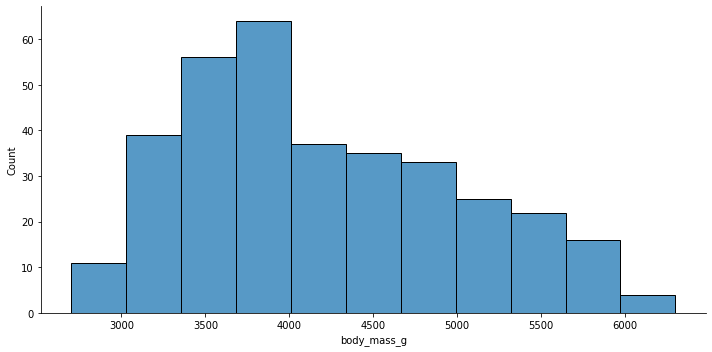

In [70]:
sns.displot(
    p,
    x = 'body_mass_g',
    aspect=2
)

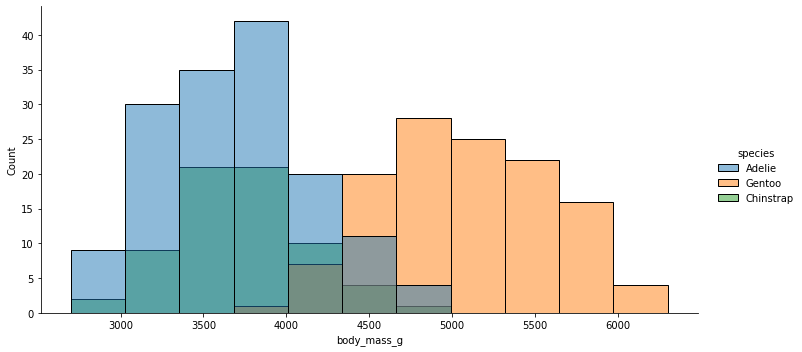

In [71]:
sns.displot(
    p,
    x = 'body_mass_g',
    hue = 'species',
    aspect=2
)

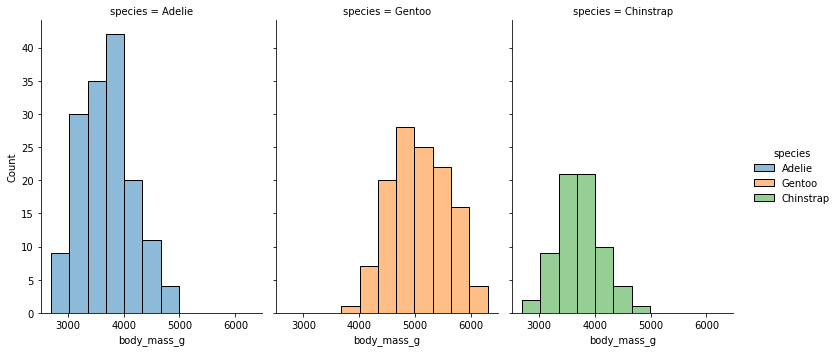

In [73]:
sns.displot(
    p,
    x = 'body_mass_g',
    hue = 'species',
    col = 'species',
    aspect=0.7
)

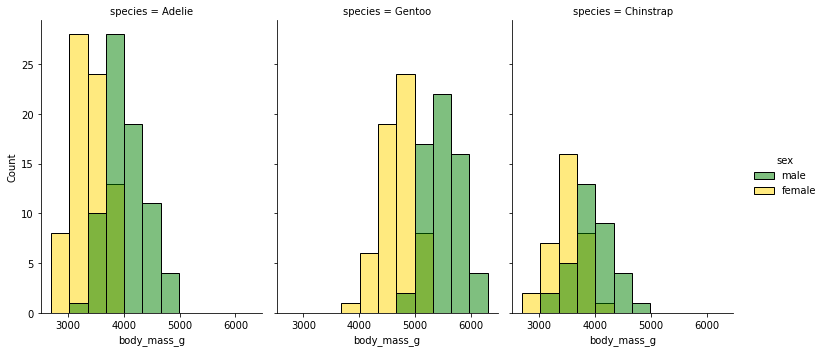

In [77]:
sns.displot(
    p,
    x = 'body_mass_g',
    hue = 'sex',
    col = 'species',
    palette = {
        'male' : 'green',
        'female' : 'gold'
    },
    aspect=0.7
)

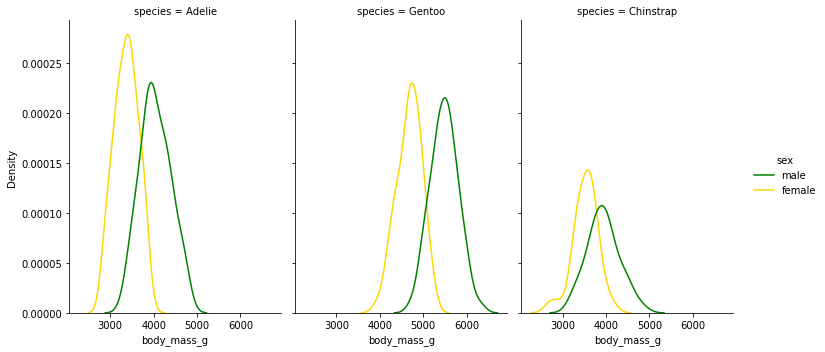

In [78]:
sns.displot(
    p,
    x = 'body_mass_g',
    hue = 'sex',
    col = 'species',
    palette = {
        'male' : 'green',
        'female' : 'gold'
    },
    aspect=0.7,
    kind='kde'
)

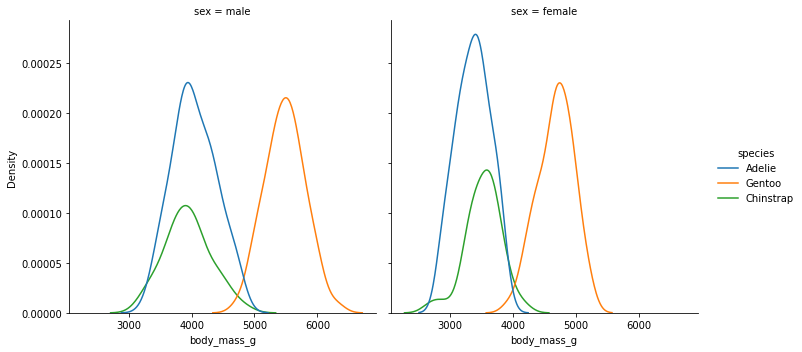

In [80]:
sns.displot(
    p,
    x = 'body_mass_g',
    hue = 'species',
    col = 'sex',
    aspect=1,
    kind='kde'
)

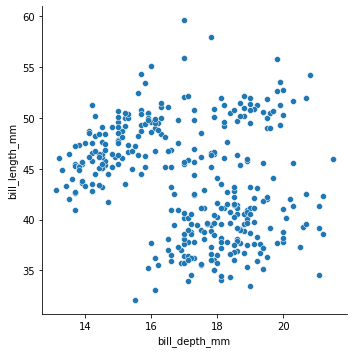

In [82]:
sns.relplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm'
)

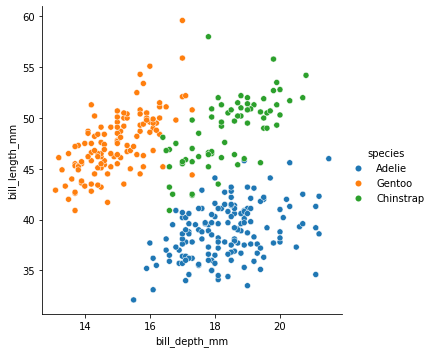

In [83]:
sns.relplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm',
    hue = 'species'
)

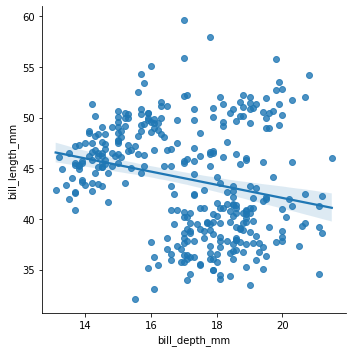

In [84]:
sns.lmplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm'
)

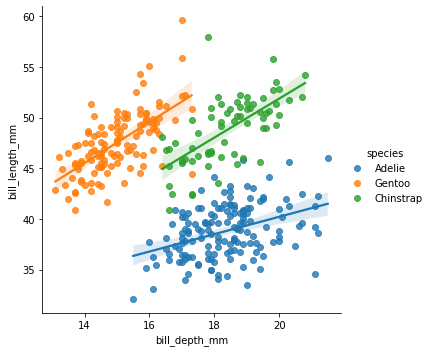

In [85]:
sns.lmplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm',
    hue = 'species'
)

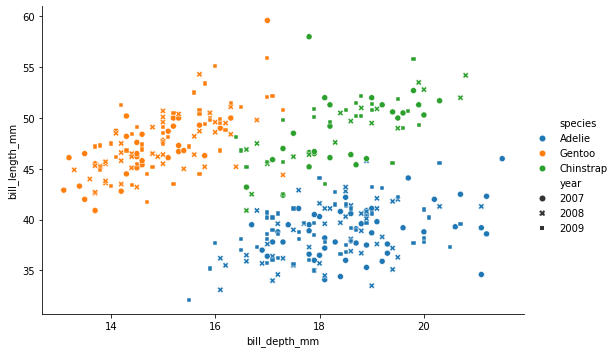

In [90]:
sns.relplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm',
    hue = 'species',
    style= 'year',
    aspect=1.5,
    height=5
)

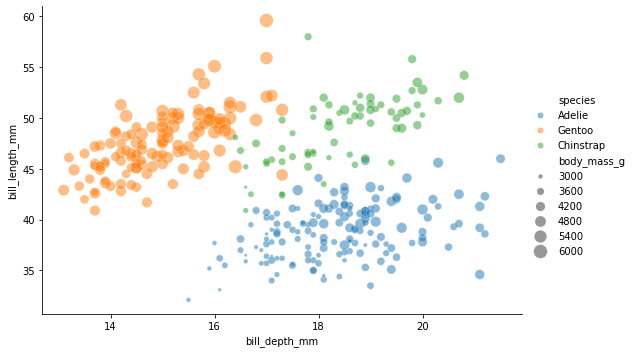

In [100]:
import matplotlib

g = sns.relplot(
    p,
    x = 'bill_depth_mm',
    y = 'bill_length_mm',
    hue = 'species',
    size= 'body_mass_g',
    sizes = (2,200),
    aspect=1.5,
    height=5,
    alpha = 0.5,
)

matplotlib.pyplot.savefig('test.png')
matplotlib.pyplot.savefig('test.svg')

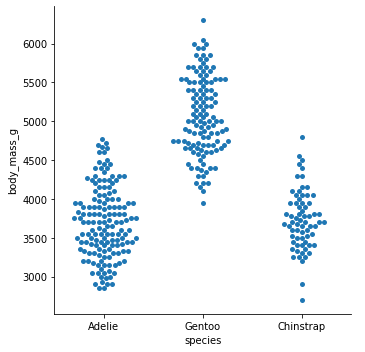

In [102]:
sns.catplot(
    p,
    x = 'species',
    y = 'body_mass_g',
    kind = 'swarm'
)

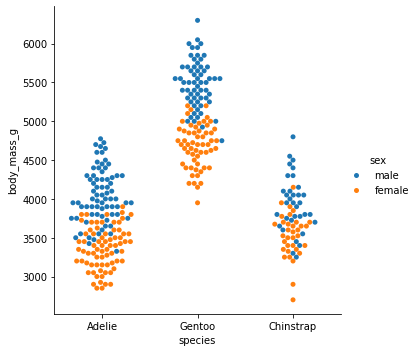

In [103]:
sns.catplot(
    p,
    x = 'species',
    y = 'body_mass_g',
    hue = 'sex',
    kind = 'swarm'
)

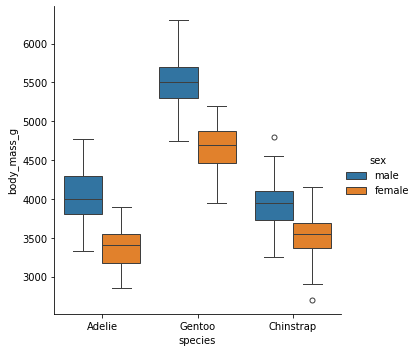

In [104]:
sns.catplot(
    p,
    x = 'species',
    y = 'body_mass_g',
    hue = 'sex',
    kind = 'box'
)

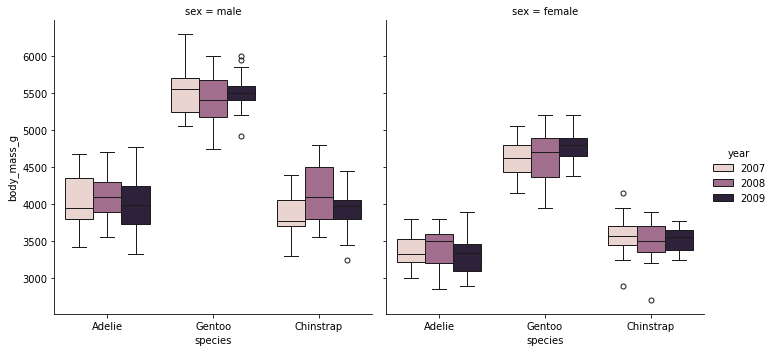

In [106]:
sns.catplot(
    p,
    x = 'species',
    y = 'body_mass_g',
    hue = 'year',
    kind = 'box',
    col='sex'
)

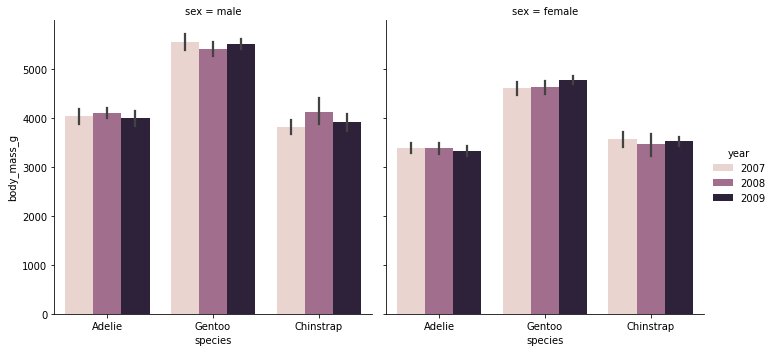

In [109]:
sns.catplot(
    p,
    x = 'species',
    y = 'body_mass_g',
    hue = 'year',
    kind = 'bar',
    col='sex'
)

In [111]:
r = pd.read_csv('/home/martin/Downloads/River Height and Flow Observations.csv')
r

,Date,Haughton Height (mAOD),Godmanchester Height (mAOD),Offord Height (mAOD),Offord Flow (Cubecs)
0,26/11/2012,8.330,9.680,11.760,150.200
1,27/11/2012,8.290,9.650,11.730,159.100
2,28/11/2012,8.280,9.660,11.770,150.200
3,29/11/2012,8.290,9.660,11.730,113.300
4,30/11/2012,8.210,9.570,11.550,68.560
...,...,...,...,...,...
2001,27/12/2018,7.775,9.069,11.223,10.120
2002,28/12/2018,7.859,9.065,11.225,8.185
2003,29/12/2018,7.755,9.079,11.247,6.954
2004,30/12/2018,7.731,9.048,11.260,6.092


In [139]:
r_tidy = r.melt(id_vars='Date')
#r_tidy = r_tidy[r_tidy['variable'] != 'Offord Flow (Cubecs)']
r_tidy

,Date,variable,value
0,26/11/2012,Haughton Height (mAOD),8.330
1,27/11/2012,Haughton Height (mAOD),8.290
2,28/11/2012,Haughton Height (mAOD),8.280
3,29/11/2012,Haughton Height (mAOD),8.290
4,30/11/2012,Haughton Height (mAOD),8.210
...,...,...,...
8019,27/12/2018,Offord Flow (Cubecs),10.120
8020,28/12/2018,Offord Flow (Cubecs),8.185
8021,29/12/2018,Offord Flow (Cubecs),6.954
8022,30/12/2018,Offord Flow (Cubecs),6.092


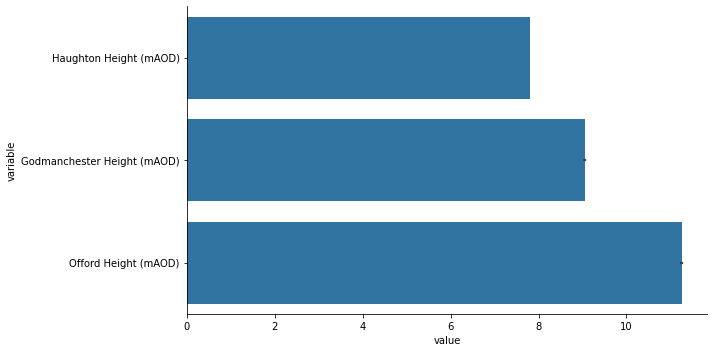

In [125]:
sns.catplot(
    r_tidy,
    y = 'variable',
    x = 'value',
    kind = 'bar',
    aspect=2
)

In [128]:
r_tidy.dtypes

Date         object
variable     object
value       float64
dtype: object

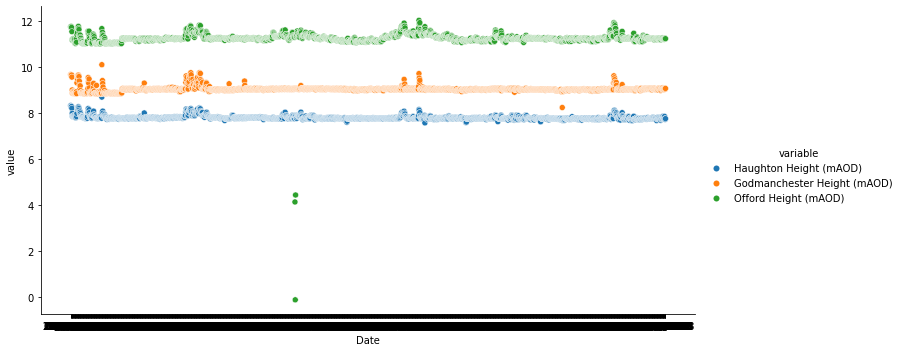

In [130]:
sns.relplot(
    r_tidy,
    x = 'Date',
    y = 'value',
    aspect = 2,
    hue = 'variable'
)

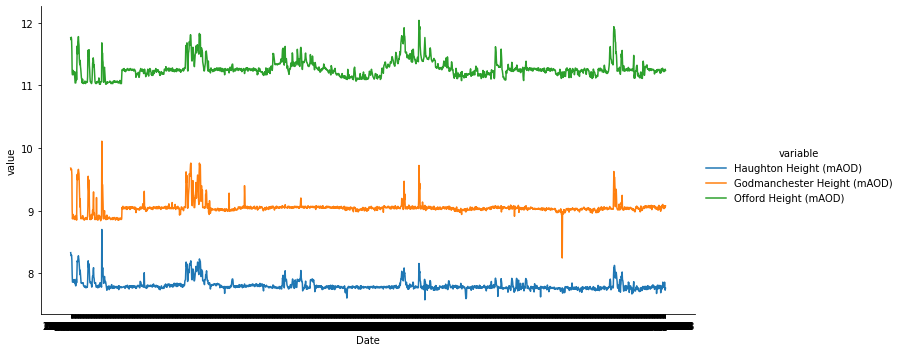

In [132]:
sns.relplot(
    r_tidy[r_tidy['value'] > 5],
    x = 'Date',
    y = 'value',
    aspect = 2,
    hue = 'variable',
    kind = 'line'
)

In [140]:
r_tidy['norm_value'] = r_tidy.drop(columns=['Date']).groupby('variable').transform(lambda x : x - x.mean())

In [141]:
r_tidy

,Date,variable,value,norm_value
0,26/11/2012,Haughton Height (mAOD),8.330,0.524346
1,27/11/2012,Haughton Height (mAOD),8.290,0.484346
2,28/11/2012,Haughton Height (mAOD),8.280,0.474346
3,29/11/2012,Haughton Height (mAOD),8.290,0.484346
4,30/11/2012,Haughton Height (mAOD),8.210,0.404346
...,...,...,...,...
8019,27/12/2018,Offord Flow (Cubecs),10.120,-4.486369
8020,28/12/2018,Offord Flow (Cubecs),8.185,-6.421369
8021,29/12/2018,Offord Flow (Cubecs),6.954,-7.652369
8022,30/12/2018,Offord Flow (Cubecs),6.092,-8.514369


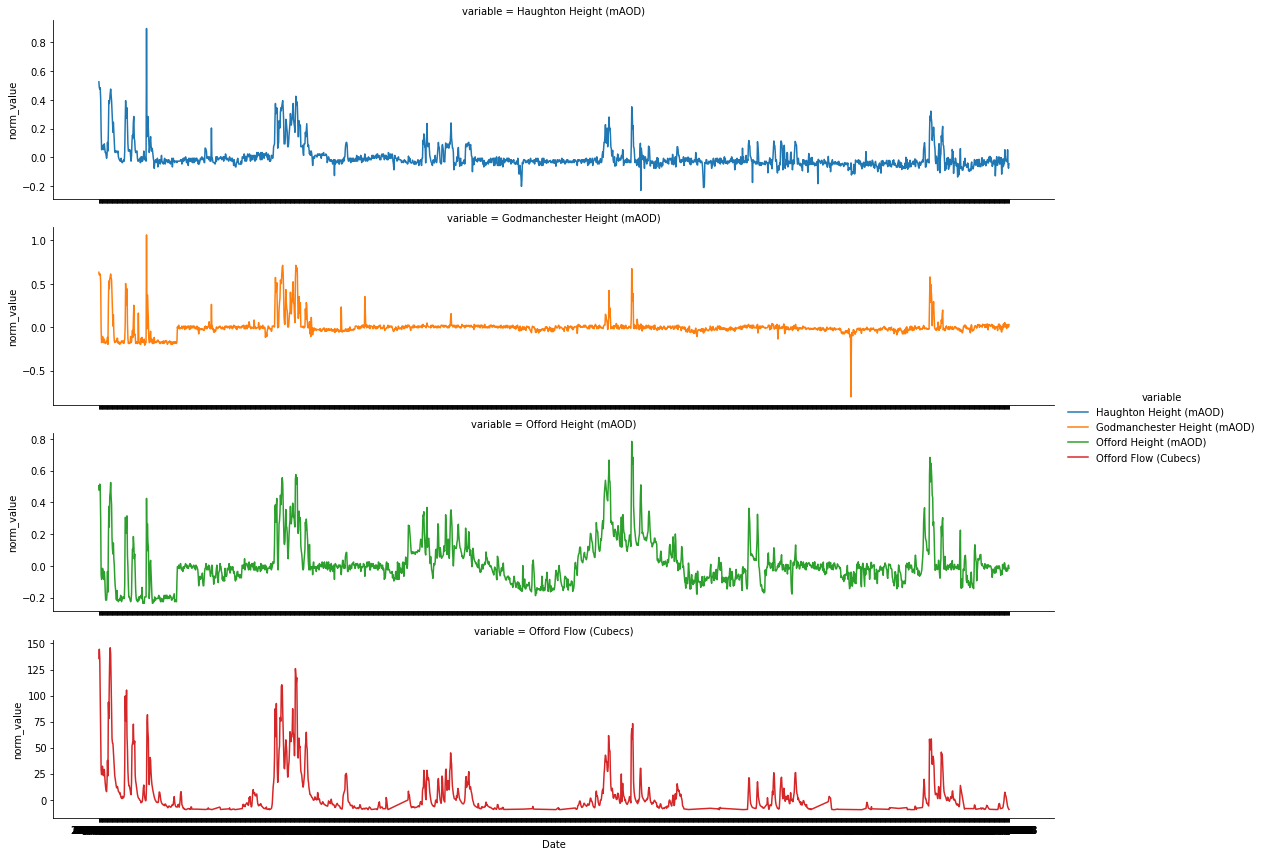

In [150]:
sns.relplot(
    r_tidy[r_tidy['value'] > 5],
    x = 'Date',
    y = 'norm_value',
    aspect = 5,
    hue = 'variable',
    kind = 'line',
    row = 'variable',
    facet_kws = {'sharey' : False},
    height=3,
)